In [2]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Pedro\curso\labs\amz_uk_price_prediction_dataset.csv")

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Analyzing Best-Seller Trends Across Product Categories

1-Crosstab Analysis:

In [6]:
# 1. Create crosstab of category vs isBestSeller
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# 2. Compute proportion of best-sellers for each category
crosstab['BestSeller_Proportion'] = crosstab[True] / (crosstab[True] + crosstab[False])

# 3. Sort categories by BestSeller_Proportion descending
crosstab_sorted = crosstab.sort_values(by='BestSeller_Proportion', ascending=False)

# 4. Display top 10 categories with highest best-seller proportion
print(crosstab_sorted.head(10))

isBestSeller                    False  True  BestSeller_Proportion
category                                                          
Grocery                          9008   556               0.058135
Smart Home Security & Lighting     98     6               0.057692
Health & Personal Care           9017   552               0.057686
Mobile Phone Accessories          248    11               0.042471
Power & Hand Tools               8353   306               0.035339
Billiard, Snooker & Pool          241     8               0.032129
Pet Supplies                     9152   285               0.030200
Home Brewing & Wine Making        239     7               0.028455
Wind Instruments                  243     7               0.028000
Mirrors                           243     7               0.028000


For "Grocery", "Smart Home Security & Lighting" and "Security & Lighting" being a best seller is more prelevant with nearly 6%, which means that products in these categories have a slightly better chance of becoming best-sellers.

2-Statistical Tests:

In [7]:
from scipy.stats import chi2_contingency

# Crosstab of category vs isBestSeller
contingency = pd.crosstab(df['category'], df['isBestSeller'])

# Perform Chi-square test
chi2, p, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi-square statistic: 36540.20
Degrees of freedom: 295
P-value: 0.0000


In [8]:
import numpy as np

# Compute Cramér's V
n = contingency.sum().sum()  # total observations
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape)-1)))

print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.122


3-Visualizations:

In [9]:
import matplotlib.pyplot as plt

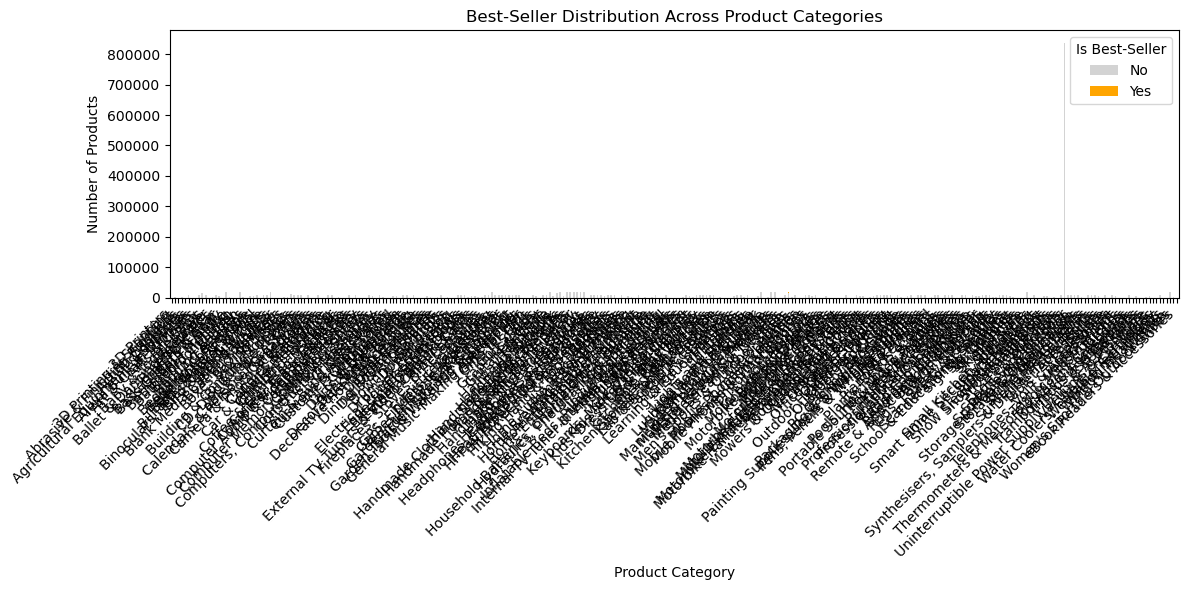

In [10]:
# Crosstab of category vs isBestSeller
category_bestseller = pd.crosstab(df['category'], df['isBestSeller'])

# Plot stacked bar chart
category_bestseller.plot(kind='bar', 
                         stacked=True, 
                         figsize=(12,6), 
                         color=['lightgray', 'orange'])

plt.title("Best-Seller Distribution Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Best-Seller", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

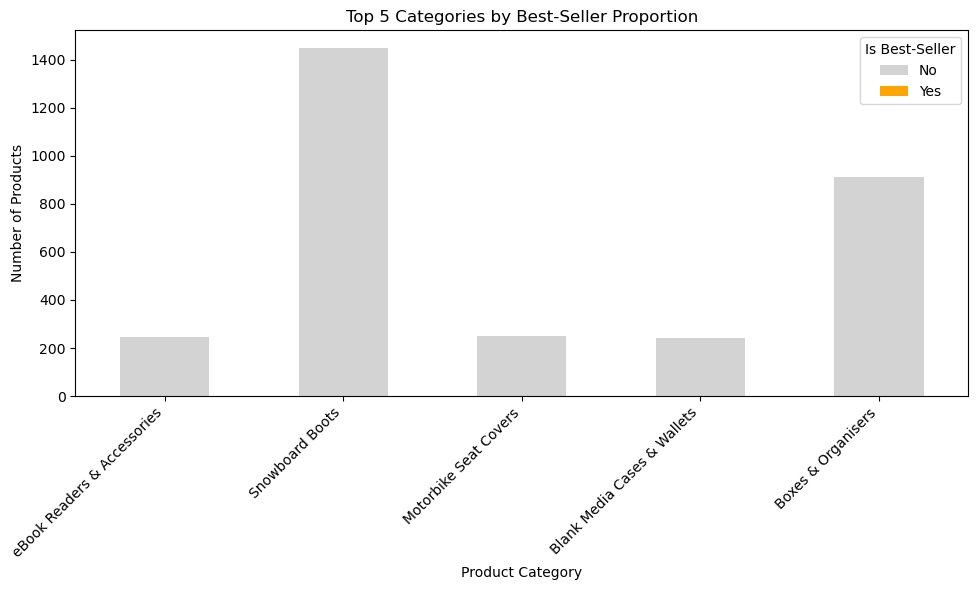

In [16]:
# Crosstab of category vs isBestSeller
category_bestseller = pd.crosstab(df['category'], df['isBestSeller'])

# Compute Best-Seller proportion
category_bestseller['BestSeller_Proportion'] = category_bestseller.iloc[:,0] / category_bestseller.sum(axis=1)  # temporary placeholder for proportion

# Select top 5 categories by Best-Seller proportion
top5_categories = category_bestseller.sort_values(by='BestSeller_Proportion', ascending=False).head(5)

# Select only the first two columns (the True/False counts) for plotting
top5_plot = top5_categories.iloc[:, :2]

# Plot stacked bar chart
top5_plot.plot(kind='bar', 
               stacked=True, 
               figsize=(10,6), 
               color=['lightgray', 'orange'])

plt.title("Top 5 Categories by Best-Seller Proportion")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Best-Seller", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

Part 2: Exploring Product Prices and Ratings Across Categories and Brands

0-Preliminary Step: Remove outliers in product prices

In [17]:
# Step 1: Calculate Q1, Q3, and IQR for the price column
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Define lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")

# Step 3: Remove outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original dataset size: {df.shape[0]}")
print(f"Dataset size after removing outliers: {df_no_outliers.shape[0]}")

Lower Bound: -44.01, Upper Bound: 99.99
Original dataset size: 2443651
Dataset size after removing outliers: 2115963


1-Violin Plots:

In [18]:
import seaborn as sns

C:\Users\pedro\AppData\Local\Temp\ipykernel_14588\3369785805.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='category', y='price', data=df_top20, inner='quartile', palette="Set2")


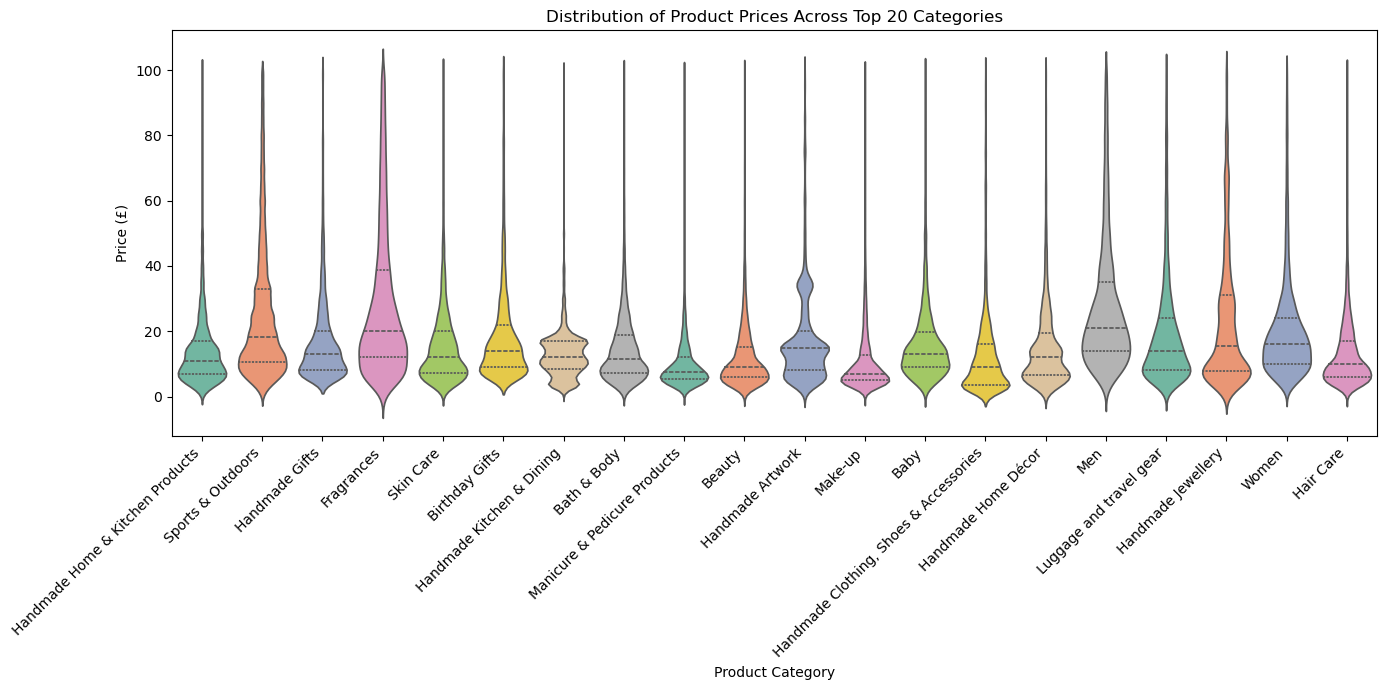

In [20]:
# Top 20 categories by product count
top20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

# Violin plot
plt.figure(figsize=(14,7))
sns.violinplot(x='category', y='price', data=df_top20, inner='quartile', palette="Set2")
plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Product Prices Across Top 20 Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

In [21]:
# Median price per category using all categories
median_prices = df_no_outliers.groupby('category')['price'].median()

# Category with highest median
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print(f"Category with highest median price: {highest_median_category} (£{highest_median_value:.2f})")

Category with highest median price: Desktop PCs (£74.00)


2-Bar Charts:

In [22]:
# Top 10 categories by product count
top10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

# Compute average price per category
avg_prices_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

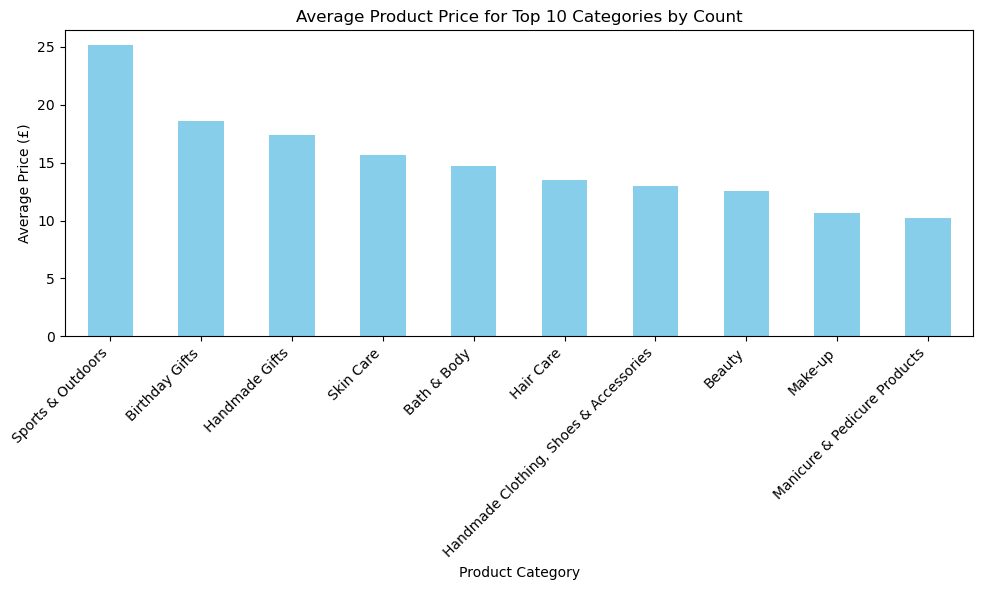

In [23]:
plt.figure(figsize=(10,6))
avg_prices_top10.plot(kind='bar', color='skyblue')
plt.title("Average Product Price for Top 10 Categories by Count")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [24]:
# Average price per category (all categories)
avg_prices_all = df_no_outliers.groupby('category')['price'].mean()

# Category with highest average price
highest_avg_category = avg_prices_all.idxmax()
highest_avg_value = avg_prices_all.max()

print(f"Category with highest average price: {highest_avg_category} (£{highest_avg_value:.2f})")

Category with highest average price: Motherboards (£68.77)


3-Box Plots:

C:\Users\pedro\AppData\Local\Temp\ipykernel_14588\411016210.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='category', y='stars', data=df_top10, palette="Set3")


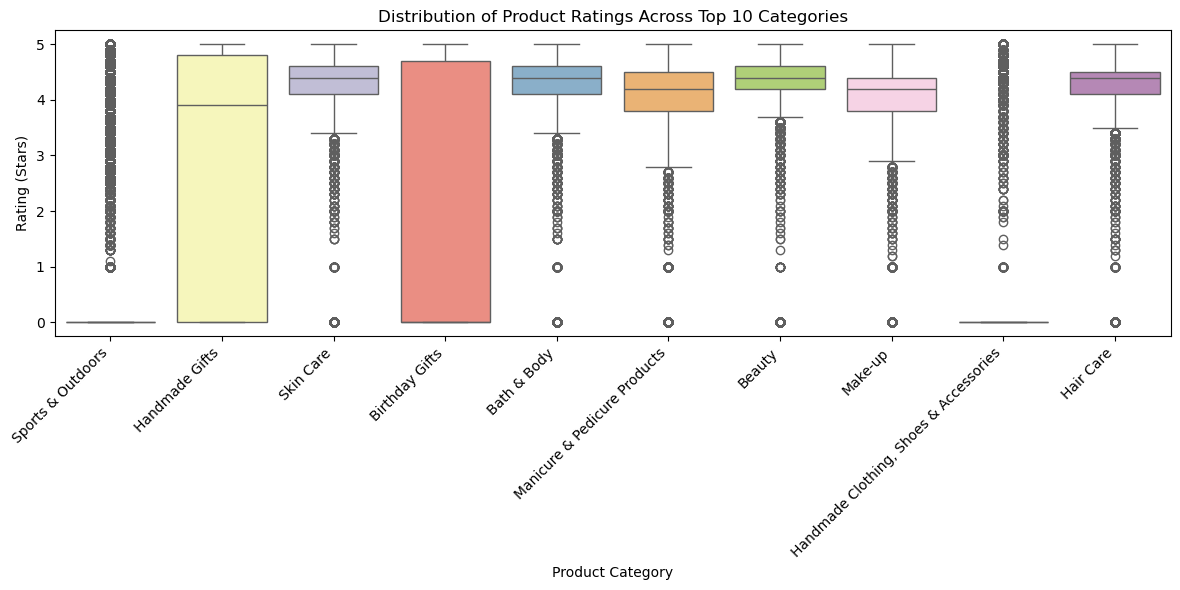

In [25]:
# Top 10 categories by product count
top10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

# Box plot
plt.figure(figsize=(12,6))
sns.boxplot(x='category', y='stars', data=df_top10, palette="Set3")
plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Product Ratings Across Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Rating (Stars)")
plt.tight_layout()
plt.show()

In [26]:
# Median rating per category (all categories)
median_ratings = df_no_outliers.groupby('category')['stars'].median()

# Category with highest median rating
highest_median_category = median_ratings.idxmax()
highest_median_value = median_ratings.max()

print(f"Category with highest median rating: {highest_median_category} ({highest_median_value} stars)")

Category with highest median rating: Computer Memory (4.7 stars)


Part 3: Investigating the Interplay Between Product Prices and Ratings

1-Correlation Coefficients:

In [27]:
# Pearson correlation between price and stars
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(f"Correlation coefficient between price and stars: {correlation:.3f}")

Correlation coefficient between price and stars: -0.078


The result is very close to 0, this means almost no correlation between product price and rating.

2-Visualizations:

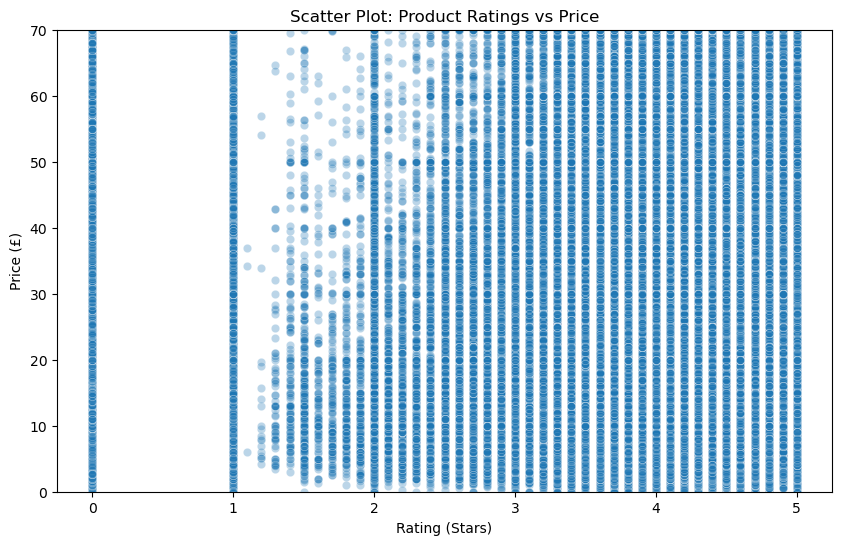

In [28]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='stars', y='price', data=df_no_outliers, alpha=0.3)
plt.title("Scatter Plot: Product Ratings vs Price")
plt.xlabel("Rating (Stars)")
plt.ylabel("Price (£)")
plt.ylim(0, df_no_outliers['price'].quantile(0.95))  # Optional: limit extreme prices for readability
plt.show()

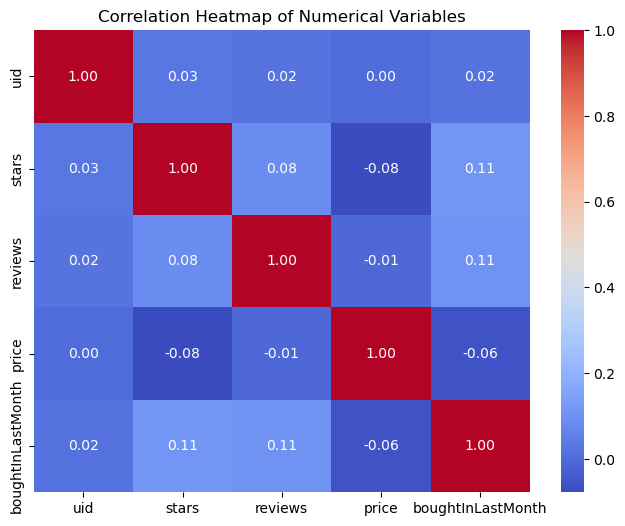

In [29]:
# Select numerical columns
numerical_cols = df_no_outliers.select_dtypes(include='number')

# Compute correlation matrix
corr_matrix = numerical_cols.corr()

# Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

In [31]:
import scipy.stats as stats

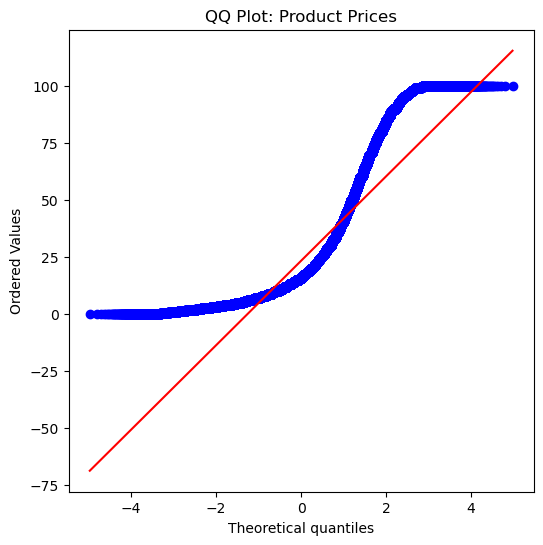

In [32]:
plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot: Product Prices")
plt.show()